# 04_1 — Optimisation du modèle et du seuil métier

**Projet 6 OpenClassrooms — Modèle de scoring crédit « Prêt à dépenser »**

**Étape 4 des consignes : « Optimisez le modèle et le seuil métier »**. Résultat attendu : un modèle avec des hyperparamètres optimisés et un seuil de décision ajusté au coût métier.

**Point de départ.** Le notebook 03_1 a comparé 8 modèles avec leurs réglages par défaut. Le meilleur est **LightGBM avec `class_weight="balanced"`** : coût métier de 0,497 en validation croisée (contre 0,807 pour la référence « tout accorder »), seuil optimal de 0,48, AUC de validation de 0,782.

**Objectif.** Chercher les hyperparamètres de LightGBM qui **minimisent directement le coût métier**, puis fixer le seuil de décision final, vérifier la robustesse du modèle, et le confronter **une seule fois** au jeu de test mis de côté depuis l'étape 1.

**Démarche**
1. Recharger les données et se connecter à MLflow.
2. Définir l'espace de recherche des hyperparamètres.
3. Écrire la fonction objectif d'Optuna : validation croisée, coût métier au seuil optimal, un run MLflow par essai.
4. Lancer l'étude et l'analyser.
5. Fixer le seuil final et contrôler la robustesse.
6. Évaluer le modèle final sur le jeu de test.

Toutes les décisions (hyperparamètres, seuil) sont prises sur le **train** en validation croisée. Le **test** ne sert qu'une fois, à la fin, pour mesurer la performance sur des clients jamais vus.

Import des bibliothèques : on ajoute Optuna, et un seul modèle est importé, LightGBM, jugé le plus performant au 03_1.

In [1]:
# -------------------------- Imports --------------------------
import os
import sys

sys.path.append("..")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"  # masque un message d'information de MLflow 3

import json

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold

sns.set()
optuna.logging.set_verbosity(optuna.logging.WARNING)  # n'affiche que les avertissements, pas une ligne par essai

from src.settings import (
    COST_FN,
    COST_FP,
    FEATURES_USED_FILE,
    ID_COLUMN,
    MLFLOW_EXPERIMENT_NAME,
    MLFLOW_TRACKING_URI,
    TARGET,
    TEST_FILE,
    TRAIN_FILE,
    random_state,
)
from src.modeling_functions import (
    cost_by_threshold,
    cross_validate_oof,
    find_best_threshold,
    scores_at_threshold,
)


## 1. Chargement des données et configuration MLflow

Chargement des données : uniquement le train et la liste des 659 features retenues à l'étape 1. Le test n'est pas chargé ici.

In [2]:
with open(FEATURES_USED_FILE, "r") as f:
    features_used = json.load(f)

train = pd.read_parquet(TRAIN_FILE)
X = train[features_used].astype("float32")
y = train[TARGET]

print(f"X : {X.shape[0]:,} lignes x {X.shape[1]} features | {X.memory_usage().sum() / 1024**2:.0f} Mo")
print(f"Taux de défaut : {y.mean():.2%} | ratio bons / mauvais clients : {(y == 0).sum() / (y == 1).sum():.1f}")


X : 246,005 lignes x 659 features | 618 Mo
Taux de défaut : 8.07% | ratio bons / mauvais clients : 11.4


Connexion à MLflow, puis lecture de la référence à battre directement dans MLflow, avec `search_runs` (API). C'est la solution d'automatisation : un futur script de réentraînement pourra comparer automatiquement le nouveau modèle à l'ancien.

In [3]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experiment = mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
dataset_abstraction = mlflow.data.from_pandas(
    train.drop(columns=ID_COLUMN), source=str(TRAIN_FILE.name), targets=TARGET, name="train_v1"
)
del train  # X et y suffisent désormais : on libère la mémoire

# Référence à battre : le meilleur run du 03_1, lu directement dans MLflow
reference_run = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.notebook = '03_1_modeles_comparaison' and tags.mlflow.runName = 'lightgbm_balanced'",
    order_by=["start_time DESC"],
    max_results=1,
).iloc[0]
reference_cost = reference_run["metrics.average_test_business_cost"]
reference_threshold = reference_run["metrics.best_threshold"]

print("Expérience :", experiment.name, "| id :", experiment.experiment_id)
print(f"Référence à battre (lightgbm_balanced, 03_1) : coût {reference_cost:.4f} au seuil {reference_threshold:.2f}")


/opt/anaconda3/envs/medef/lib/python3.12/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


Expérience : scoring_credit | id : 1
Référence à battre (lightgbm_balanced, 03_1) : coût 0.4966 au seuil 0.48


## 2. Pourquoi optimiser, et pourquoi Optuna ?

Cette section justifie un choix de méthode : ici Optuna plutôt que GridSearchCV. La cellule ci-dessous estime le temps nécessaire pour rechercher les hyperparamètres. Avec environ 9 s par entraînement, la grille donne 78 125 combinaisons, soit à peu près 1 000 heures (environ 40 jours). Avec Optuna, 40 essais étaient estimés à environ 30 minutes (en pratique, les essais les plus lourds ont été bien plus longs, voir section 5). L'écart parle de lui-même.

On optimise car, pour l'instant, LightGBM tournait avec ses réglages par défaut, qui sont pensés pour marcher « partout » et non précisément pour notre problème. Les hyperparamètres règlent le compromis entre sous-apprentissage et surapprentissage, notamment :
- la complexité des arbres (`num_leaves`) ;
- la vitesse d'apprentissage (`learning_rate` et `n_estimators`) ;
- l'aléa (`subsample`, `colsample_bytree`) ;
- la régularisation (`reg_lambda`).

Notre objectif n'est pas de maximiser l'AUC mais de minimiser le coût métier.

Il existe traditionnellement 3 méthodes possibles :

| Méthode                | Principe                                                 | Limite                                     |
| ---------------------- | -------------------------------------------------------- | ------------------------------------------ |
| **GridSearchCV**       | Teste **toutes** les combinaisons d'une grille           | Explosion combinatoire (voir la cellule)   |
| **RandomizedSearchCV** | Tire **au hasard** N combinaisons                        | Ne tire aucune leçon des essais précédents |
| **Optuna (TPE)**       | **Apprend** des essais passés pour proposer les suivants | Légère complexité de mise en place         |

Comment Optuna apprend-il ?
Le `TPESampler` d'Optuna utilise l'algorithme *Tree-structured Parzen Estimator*, une méthode d'optimisation bayésienne adaptée à la recherche d'hyperparamètres. Optuna sépare l'historique des essais en deux groupes selon la valeur de la fonction objectif : « bons » et « mauvais ». Il modélise ensuite chaque groupe par une densité (mélanges de gaussiennes) pour proposer de nouveaux réglages qui ressemblent aux bons. Ici, notre critère n'est pas un score standard : pour chaque essai, il faut chercher le seuil optimal sur les prédictions hors pli, puis calculer le coût.

In [4]:
grid = {
    "n_estimators": [200, 400, 600, 800, 1000],
    "learning_rate": [0.01, 0.02, 0.05, 0.1, 0.2],
    "num_leaves": [15, 31, 63, 127, 255],
    "min_child_samples": [10, 20, 50, 100, 200],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.3, 0.5, 0.7, 0.9, 1.0],
    "reg_lambda": [0, 0.1, 1, 10, 100],
}
n_combinations = np.prod([len(values) for values in grid.values()])
n_folds = 5
fit_time = reference_run["metrics.average_fit_time_s"]  # temps moyen d'un entraînement au 03_1, lu dans MLflow

grid_hours = n_combinations * n_folds * fit_time / 3600
print(f"Grille complète : {n_combinations:,} combinaisons x {n_folds} plis x {fit_time:.0f} s = {grid_hours:,.0f} heures ({grid_hours / 24:,.0f} jours)")

n_trials = 40
print(f"Optuna, {n_trials} essais : {n_trials * n_folds * fit_time / 60:.0f} minutes environ (plus si les essais ont beaucoup d'arbres)")


Grille complète : 78,125 combinaisons x 5 plis x 9 s = 1,013 heures (42 jours)
Optuna, 40 essais : 31 minutes environ (plus si les essais ont beaucoup d'arbres)


## 3. L'espace de recherche des hyperparamètres

La cellule suivante définit l'espace de recherche ; elle n'entraîne rien. Elle affiche seulement le modèle construit avec les réglages par défaut.

Un nombre d'arbres successifs trop important (par exemple 2 000) serait problématique à cause du budget de calcul. L'espace de recherche est un compromis entre la liberté laissée à Optuna et le temps disponible.

In [5]:
FIXED_PARAMS = {
    "class_weight": "balanced",  # retenu au 03_1
    "subsample_freq": 1,  # sans lui, LightGBM ignore subsample
    "random_state": random_state,
    "n_jobs": -1,
    "verbose": -1,
}


def suggest_params(trial: optuna.Trial) -> dict:
    """Hyperparamètres proposés par Optuna pour un essai."""
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 300, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }


def build_model(params: dict) -> LGBMClassifier:
    return LGBMClassifier(**FIXED_PARAMS, **params)


# Réglages par défaut de LightGBM (ceux du 03_1), dans l'espace de recherche : servira de premier essai
DEFAULT_PARAMS = {
    "n_estimators": 100,
    "learning_rate": 0.1,
    "num_leaves": 31,
    "min_child_samples": 20,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "reg_alpha": 1e-3,
    "reg_lambda": 1e-3,
}
build_model(DEFAULT_PARAMS)


,class_weight,'balanced'
,subsample_freq,1
,reg_alpha,0.001
,reg_lambda,0.001
,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1


## 4. La fonction objectif : le coût métier en validation croisée

C'est le cœur du notebook. Optuna ne connaît rien au crédit (ni au coût métier) : il appelle une fonction que nous lui fournissons, reçoit un nombre et cherche à le rendre le plus petit possible. Tout notre savoir-faire métier est donc dans cette fonction.

À chaque essai, la fonction objectif :
1. reçoit les hyperparamètres proposés par Optuna (`suggest_params`) ;
2. lance une validation croisée en 5 plis, avec les mêmes plis qu'au 03_1 (même `random_state`) : on obtient les prédictions hors pli ;
3. recherche le seuil qui minimise le coût sur ces prédictions ;
4. calcule le coût pli par pli à ce seuil : moyenne et écart-type ;
5. enregistre le tout dans un run MLflow enfant ;
6. renvoie le coût métier moyen à Optuna : c'est le nombre qu'il cherche à minimiser.

Précisions :
- On optimise le couple (hyperparamètres, seuil), pas les hyperparamètres seuls. Chaque essai est jugé à son meilleur seuil. Sans cela, un modèle aux probabilités « décalées » serait injustement pénalisé au seuil de 0,5 alors qu'il serait excellent à 0,3.
- Pourquoi les mêmes plis qu'au 03_1 ? Pour comparer à armes égales avec la référence (0,497) : une différence de coût viendra des hyperparamètres, pas du hasard du découpage.

Dans la section suivante, nous apportons une nouveauté dans notre usage de MLflow : on ouvre un run parent (« l'étude Optuna »), et chaque essai crée un run enfant à l'intérieur. Un essai = 5 entraînements (un par pli). Au notebook précédent, un entraînement LightGBM prenait environ 9 secondes ; avec plus d'arbres, il faut plutôt compter 15 à 20 secondes. Un essai prend donc environ 1 minute, et 40 essais prendraient 30 à 45 minutes. Il faut arbitrer entre le budget de calcul (temps et ressources de l'ordinateur) et la recherche de l'optimum absolu, auquel on renonce volontairement.

In [6]:
n_splits = 5
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)  # mêmes plis qu'au 03_1


def objective(trial: optuna.Trial) -> float:
    """Un essai Optuna = un jeu d'hyperparamètres évalué en validation croisée = un run MLflow enfant."""
    params = suggest_params(trial)

    with mlflow.start_run(
        run_name=f"trial_{trial.number:02d}",
        nested=True,
        tags={"etape": "4 - optimisation", "notebook": "04_1_optimisation_seuil", "optuna_trial": trial.number},
    ):
        oof_proba, val_indices, fold_scores = cross_validate_oof(build_model(params), X, y, cv)
        best_threshold, _ = find_best_threshold(y, oof_proba)
        scores = scores_at_threshold(y, oof_proba, val_indices, best_threshold)

        metrics = {
            "average_train_roc_auc": np.mean(fold_scores["train_roc_auc"]),
            "average_test_roc_auc": np.mean(fold_scores["test_roc_auc"]),
            "test_roc_auc_std": np.std(fold_scores["test_roc_auc"]),
            "best_threshold": best_threshold,
            "average_fit_time_s": np.mean(fold_scores["fit_time"]),
            **scores,
        }
        metrics["overfit_gap_roc_auc"] = metrics["average_train_roc_auc"] - metrics["average_test_roc_auc"]

        mlflow.log_params(params)
        mlflow.log_metrics(metrics)

    # Informations gardées aussi côté Optuna, pour l'analyse de l'étude (section 6)
    trial.set_user_attr("best_threshold", best_threshold)
    trial.set_user_attr("average_test_roc_auc", metrics["average_test_roc_auc"])
    trial.set_user_attr("overfit_gap_roc_auc", metrics["overfit_gap_roc_auc"])

    return metrics["average_test_business_cost"]


## 5. Lancement de l'étude Optuna

L'étude a été lancée avec un budget de 40 essais. Face au temps de calcul (essais de plus en plus lourds, saturation de la mémoire du Mac), elle a été interrompue manuellement après **25 essais terminés**. Comme chaque essai était enregistré dans MLflow au fur et à mesure, rien n'a été perdu : après le redémarrage de la machine, l'étude est reconstruite à partir des runs MLflow, sans réentraîner aucun modèle.

La cellule de lancement est conservée pour la traçabilité, mais désactivée (`RUN_STUDY = False`) : le notebook peut ainsi être réexécuté en entier en quelques minutes.

In [7]:
RUN_STUDY = False  # True : relance l'étude complète (plusieurs heures sur le Mac) ; False : reconstruction depuis MLflow (cellule suivante)
n_trials = 40  # budget de calcul (voir section 2)

if RUN_STUDY:
    study = optuna.create_study(
        study_name="lightgbm_balanced_cout_metier",
        direction="minimize",  # on cherche le coût métier le plus BAS
        sampler=optuna.samplers.TPESampler(seed=random_state),  # reproductible
    )
    study.enqueue_trial(DEFAULT_PARAMS)  # essai n°0 = réglages par défaut du 03_1

    with mlflow.start_run(
        run_name="optuna_lightgbm_balanced",
        tags={"etape": "4 - optimisation", "notebook": "04_1_optimisation_seuil", "famille_modele": "boosting",
              "gestion_desequilibre": "class_weight", "type_run": "etude_optuna"},
        description=f"Étude Optuna (TPE, {n_trials} essais) sur LightGBM balanced : minimisation du coût métier "
                    f"au seuil optimal, validation croisée 5 plis. Chaque essai est un run enfant.",
    ):
        mlflow.log_input(dataset_abstraction, context="training")
        mlflow.log_params({"n_trials": n_trials, "sampler": "TPE", "n_splits": n_splits,
                           "cost_fn": COST_FN, "cost_fp": COST_FP, **FIXED_PARAMS})
        study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
else:
    print("Étude non relancée : elle est reconstruite à partir des runs MLflow (cellule suivante).")

Étude non relancée : elle est reconstruite à partir des runs MLflow (cellule suivante).


In [8]:
# -------------------------- Reconstruction de l'étude à partir des runs MLflow --------------------------
# Le run parent de l'étude de 40 essais (interrompue) est le plus récent
parent_run = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.mlflow.runName = 'optuna_lightgbm_balanced'",
    order_by=["start_time DESC"],
    max_results=1,
).iloc[0]

# Ses runs enfants terminés = les essais complets
trial_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent_run['run_id']}' and attributes.status = 'FINISHED'",
    order_by=["start_time ASC"],
)

# Mêmes intervalles que suggest_params (section 3)
distributions = {
    "n_estimators": optuna.distributions.IntDistribution(100, 800, step=50),
    "learning_rate": optuna.distributions.FloatDistribution(0.01, 0.2, log=True),
    "num_leaves": optuna.distributions.IntDistribution(8, 128, log=True),
    "min_child_samples": optuna.distributions.IntDistribution(10, 300, log=True),
    "subsample": optuna.distributions.FloatDistribution(0.6, 1.0),
    "colsample_bytree": optuna.distributions.FloatDistribution(0.2, 1.0),
    "reg_alpha": optuna.distributions.FloatDistribution(1e-3, 10, log=True),
    "reg_lambda": optuna.distributions.FloatDistribution(1e-3, 10, log=True),
}

study = optuna.create_study(study_name="lightgbm_balanced_cout_metier", direction="minimize")
for _, run in trial_runs.iterrows():
    params = {
        name: int(run[f"params.{name}"]) if isinstance(dist, optuna.distributions.IntDistribution) else float(run[f"params.{name}"])
        for name, dist in distributions.items()
    }  # MLflow stocke les paramètres en texte : on les reconvertit en nombres
    study.add_trial(
        optuna.trial.create_trial(
            params=params,
            distributions=distributions,
            value=run["metrics.average_test_business_cost"],
            user_attrs={
                "best_threshold": run["metrics.best_threshold"],
                "average_test_roc_auc": run["metrics.average_test_roc_auc"],
                "overfit_gap_roc_auc": run["metrics.overfit_gap_roc_auc"],
                "average_fit_time_s": run["metrics.average_fit_time_s"],
            },
        )
    )

print(f"Run parent : {parent_run['run_id']} (statut {parent_run['status']}, lancé le {parent_run['start_time']:%d/%m %H:%M})")
print(f"Étude reconstruite : {len(study.trials)} essais | meilleur : n°{study.best_trial.number}, coût {study.best_value:.4f}")


Run parent : 8519dba63359467ba4989f6e55fc242a (statut FINISHED, lancé le 02/11 12:37)
Étude reconstruite : 25 essais | meilleur : n°17, coût 0.4873


In [9]:
# -------------------------- Clôture de l'étude interrompue à 25 essais --------------------------
completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
best = study.best_trial  # Optuna ne tient compte que des essais terminés

parent_run = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.mlflow.runName = 'optuna_lightgbm_balanced'",
    order_by=["start_time DESC"],
    max_results=1,
).iloc[0]

with mlflow.start_run(run_id=parent_run["run_id"]):  # on rouvre le run parent pour y écrire le résumé
    mlflow.set_tag("note_interruption", f"étude arrêtée manuellement après {len(completed)} essais (temps de calcul)")
    mlflow.log_param("n_trials_completed", len(completed))
    mlflow.log_params({f"best_{name}": value for name, value in best.params.items()})
    mlflow.log_metrics({
        "best_business_cost": best.value,
        "best_threshold": best.user_attrs["best_threshold"],
        "best_test_roc_auc": best.user_attrs["average_test_roc_auc"],
        "best_overfit_gap_roc_auc": best.user_attrs["overfit_gap_roc_auc"],
        "gain_vs_reference": reference_cost - best.value,
    })

print(f"{len(completed)} essais terminés | meilleur : n°{best.number} | coût {best.value:.4f} "
      f"(référence 03_1 : {reference_cost:.4f}) | seuil {best.user_attrs['best_threshold']:.2f}")
best.params


25 essais terminés | meilleur : n°17 | coût 0.4873 (référence 03_1 : 0.4966) | seuil 0.48


{'n_estimators': 650,
 'learning_rate': 0.02140362201994293,
 'num_leaves': 37,
 'min_child_samples': 180,
 'subsample': 0.9987995375430284,
 'colsample_bytree': 0.5829387158778291,
 'reg_alpha': 1.5545896925729108,
 'reg_lambda': 0.0565831061129996}

## 6. Analyse de l'étude

Analyse de l'historique, de l'importance des hyperparamètres, puis des meilleurs essais.

Le graphique suivant retrace l'historique de l'étude : chaque point bleu est un essai, la ligne rouge en escalier est le meilleur coût trouvé jusque-là. La zone grise correspond aux 10 premiers essais, faits au hasard par TPE avant qu'il commence à apprendre. La ligne noire est la référence du notebook 03_1.

Sur le graphique :
- **Contrôle de non-régression.** L'essai 0 (réglages par défaut) obtient un coût de 0,4973, contre 0,4966 pour la référence du 03_1. L'écart (0,0007) vient d'une seule différence : la régularisation (`reg_alpha`, `reg_lambda`) vaut 0,001 au lieu de 0, car une échelle logarithmique ne peut pas contenir 0. Cet écart est très inférieur à l'écart-type entre plis (environ 0,005) : le protocole du 04_1 reproduit bien celui du 03_1, et les résultats sont comparables.
- **Budget d'essais.** Le meilleur essai est le n°17. La ligne rouge reste ensuite plate jusqu'à l'essai 24 : 7 essais sans progrès. On peut en conclure que le budget de 25 essais était raisonnable : continuer aurait probablement apporté peu.
- **Apprentissage de TPE.** Après l'essai 10, les points bleus se resserrent vers le bas, alors qu'ils sont plus dispersés dans la zone grise. C'est l'effet de TPE : il apprend des essais passés et propose des réglages de plus en plus prometteurs au fil de l'étude.
- **Ampleur du gain.** Le meilleur essai atteint un coût de 0,4873, contre 0,4966 pour la référence : un gain de 0,0093 (environ −1,9 %). Ce gain est près de 2 fois supérieur à l'écart-type entre plis (0,005) : ce n'est donc pas un effet du hasard du découpage. Il reste toutefois modeste à côté du gain obtenu au 03_1 grâce au seuil et à la pondération (0,807 → 0,497) : l'optimisation des hyperparamètres **affine** le modèle, l'essentiel du gain venait du traitement du coût métier.

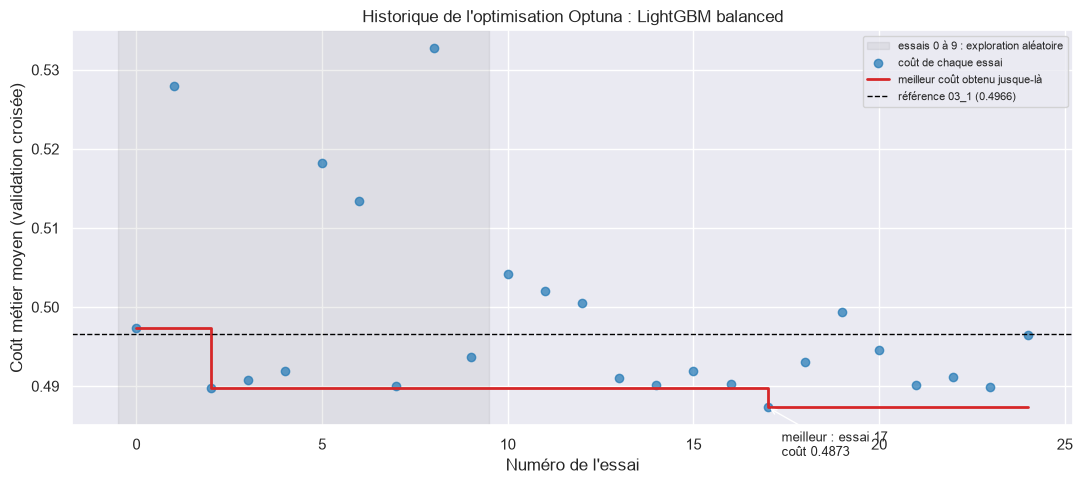

Essai 0 (réglages par défaut) : 0.4973 | référence 03_1 : 0.4966
Essais sous la référence : 16 sur 25


In [10]:
from src.settings import FIGURES_PATH

trials_df = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
trials_df["meilleur_jusque_la"] = trials_df["value"].cummin()

fig, ax = plt.subplots(figsize=(11, 5))
ax.axvspan(-0.5, 9.5, color="grey", alpha=0.12, label="essais 0 à 9 : exploration aléatoire")
ax.scatter(trials_df["number"], trials_df["value"], color="tab:blue", alpha=0.7, label="coût de chaque essai")
ax.step(trials_df["number"], trials_df["meilleur_jusque_la"], where="post", color="tab:red", lw=2,
        label="meilleur coût obtenu jusque-là")
ax.axhline(reference_cost, color="black", ls="--", lw=1, label=f"référence 03_1 ({reference_cost:.4f})")
ax.annotate(f"meilleur : essai {study.best_trial.number}\ncoût {study.best_value:.4f}",
            xy=(study.best_trial.number, study.best_value), xytext=(10, -35), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_xlabel("Numéro de l'essai")
ax.set_ylabel("Coût métier moyen (validation croisée)")
ax.set_title("Historique de l'optimisation Optuna : LightGBM balanced")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()

fig.savefig(FIGURES_PATH / "04_1_historique_optuna.png", dpi=120)
with mlflow.start_run(run_id=parent_run["run_id"]):
    mlflow.log_figure(fig, "historique_optuna.png")
plt.show()

print(f"Essai 0 (réglages par défaut) : {trials_df.loc[0, 'value']:.4f} | référence 03_1 : {reference_cost:.4f}")
print(f"Essais sous la référence : {(trials_df['value'] < reference_cost).sum()} sur {len(trials_df)}")


Quels hyperparamètres ont vraiment compté?

Pour le graphique suivant, pour chaque hyperparamètre, la part de la variation du coût qu'il explique, selon la méthode *functional ANOVA* (fANOVA). Ici, Optuna ajuste un petit modèle (réglages -> coût) sur les 25 essais. Puis il mesure combien le coût varie quand chaque hyperparamètre bouge seul. Le total fait 100%.

Le deuxième graphique montre, pour les deux hyperparamètres les plus influents (ici `subsample` et `n_estimators`), le coût de chaque essai en fonction de leur valeur. Le meilleur essai est en rouge. Sur les nuages de points, la question à se poser est de savoir si la zone du meilleur essai est au bord de l'intervalle de recherche : si oui, l'optimum est peut-être en dehors, et il faudrait élargir l'intervalle lors d'une prochaine étude.

Limite : avec seulement 25 essais, ces importances sont indicatives, pas définitives. Ici peu de points permettent l'ajustement de fANOVA.
Dans une démarche MLOps, savoir quels hyperparamètres comptent permet, lors d'un réentraînement futur, de réduire l'espace de recherche aux paramètres utiles. L'optimisation devient alors plus rapide et moins coûteuse. 

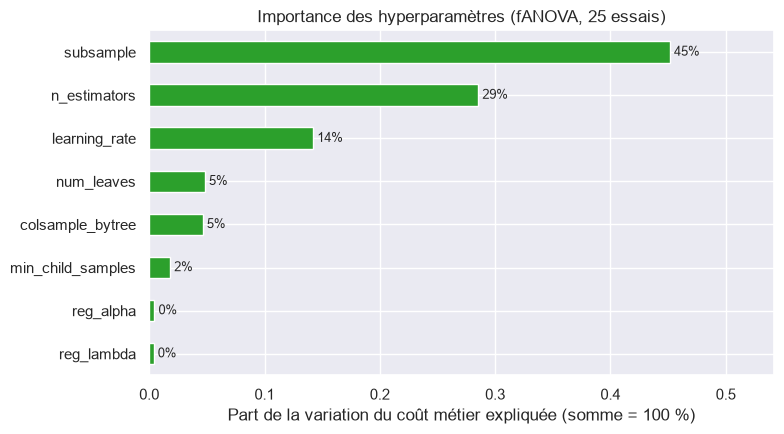

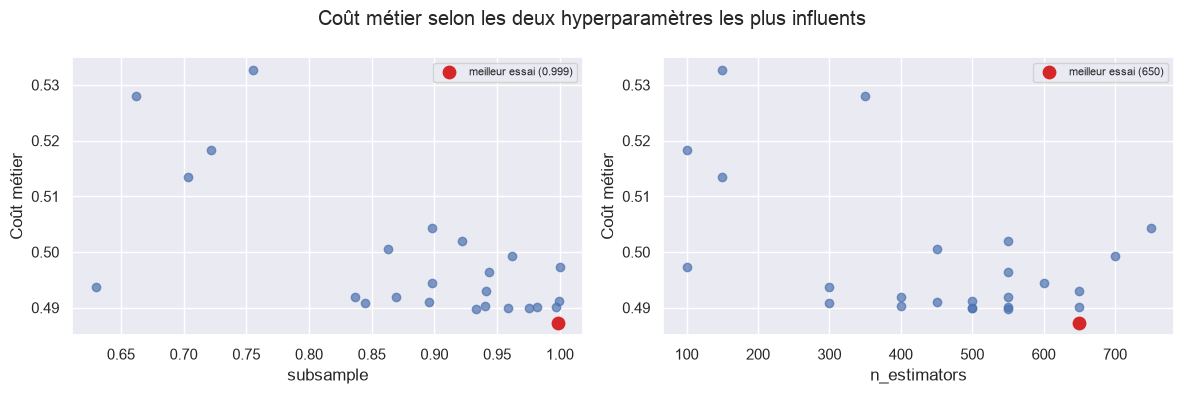

In [11]:
importances = pd.Series(
    optuna.importance.get_param_importances(
        study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=random_state)
    )
).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
importances.plot.barh(ax=ax, color="tab:green")
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in importances], fontsize=9, padding=3)
ax.set_xlabel("Part de la variation du coût métier expliquée (somme = 100 %)")
ax.set_title("Importance des hyperparamètres (fANOVA, 25 essais)")
ax.set_xlim(0, importances.max() * 1.2)
plt.tight_layout()

fig.savefig(FIGURES_PATH / "04_1_importance_hyperparametres.png", dpi=120)
with mlflow.start_run(run_id=parent_run["run_id"]):
    mlflow.log_figure(fig, "importance_hyperparametres.png")
plt.show()

# Valeurs des 2 hyperparamètres les plus importants, essai par essai
top_two = importances.index[-2:][::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, top_two):
    ax.scatter(trials_df[f"params_{name}"], trials_df["value"], alpha=0.7)
    best_value = study.best_params[name]
    ax.scatter(best_value, study.best_value, color="tab:red", s=80, label=f"meilleur essai ({best_value:.3g})")
    if distributions[name].log:
        ax.set_xscale("log")
    ax.set_xlabel(name)
    ax.set_ylabel("Coût métier")
    ax.legend(fontsize=8)
fig.suptitle("Coût métier selon les deux hyperparamètres les plus influents")
plt.tight_layout()
plt.show()


Les meilleurs essais, et le choix du modèle final.

In [12]:
columns = {
    "number": "essai",
    "value": "coût métier",
    "user_attrs_best_threshold": "seuil",
    "user_attrs_average_test_roc_auc": "AUC val",
    "user_attrs_overfit_gap_roc_auc": "écart AUC train-val",
    "user_attrs_average_fit_time_s": "temps / pli (s)",
    "params_n_estimators": "n_estimators",
    "params_learning_rate": "learning_rate",
    "params_num_leaves": "num_leaves",
    "params_min_child_samples": "min_child_samples",
}
top_trials = trials_df.sort_values("value").head(8)[list(columns)].rename(columns=columns).set_index("essai")

# Écart au meilleur essai, exprimé en écarts-types entre plis
best_std = trial_runs.set_index(trial_runs["tags.mlflow.runName"].str[-2:].astype(int))["metrics.test_business_cost_std"]
top_trials["écart au meilleur (en écarts-types)"] = (top_trials["coût métier"] - study.best_value) / best_std[study.best_trial.number]

top_trials.style.format(precision=4).format(
    {"temps / pli (s)": "{:.0f}", "learning_rate": "{:.3f}", "écart au meilleur (en écarts-types)": "{:.2f}"}
).background_gradient(subset=["coût métier", "écart AUC train-val", "temps / pli (s)"], cmap="RdYlGn_r")


,coût métier,seuil,AUC val,écart AUC train-val,temps / pli (s),n_estimators,learning_rate,num_leaves,min_child_samples,écart au meilleur (en écarts-types)
essai,,,,,,,,,,
17,0.487319,0.480000,0.786570,0.082757,61,650,0.021,37,180,0.00
2,0.489823,0.490000,0.784697,0.047663,26,550,0.083,8,271,0.49
23,0.489929,0.470000,0.784896,0.100479,158,500,0.014,88,94,0.51
7,0.490006,0.450000,0.785891,0.143826,78,500,0.017,118,138,0.53
21,0.490136,0.480000,0.786572,0.101033,77,650,0.019,53,95,0.55
14,0.490153,0.470000,0.785879,0.126830,64,550,0.019,80,143,0.55
16,0.490226,0.470000,0.785527,0.078278,42,400,0.060,22,278,0.57
3,0.490775,0.500000,0.784796,0.061081,18,300,0.048,26,26,0.68


Le tableau ci-dessus affiche les 8 meilleurs essais, du meilleur au moins bon, avec un dégradé de couleurs. Il montre le coût métier, la robustesse, le surapprentissage, le temps de calcul et les principaux hyperparamètres. La dernière colonne indique l'écart de chaque essai au meilleur, mesuré en écarts-types entre plis.

Le choix du modèle final se joue entre l'essai 2 et l'essai 17.

L'essai 2 coûte à peine plus cher : 0,49 écart-type, ce qui reste dans le bruit du découpage en plis. En revanche, il surapprend près de 2 fois moins (écart AUC train-val), il est 2 fois plus rapide (temps par pli) et il est plus simple (arbres à 8 feuilles au lieu de 37).

L'essai 17 minimise effectivement le critère métier, mais au prix d'un surapprentissage et d'un temps de calcul plus élevés.

L'essai 2 est le meilleur arbitrage. C'est la règle de parcimonie : parmi les modèles dont le coût est à moins d'un écart-type du meilleur, on préfère le plus simple.
- Il surapprend moins : il a donc de meilleures chances de tenir sur des clients jamais vus, au moment du test puis en production.
- Il est plus rapide : dans une démarche MLOps, le réentraînement régulier prend du temps, chaque minute économisée compte.
- Le meilleur essai (le 17) a pu bénéficier en partie d'un biais de sélection.

## 7. Modèle final : courbe coût / seuil et choix du seuil

Après avoir étudié les hyperparamètres et sélectionné l'essai Optuna retenu (essai n°2, règle de parcimonie), nous refaisons ses prédictions hors pli et sélectionnons le seuil final.

La cellule ci-dessous récupère les hyperparamètres de l'essai choisi, refait sa validation croisée et trace la courbe coût / seuil demandée explicitement par la consigne. Ce graphique permet aussi de mesurer l'écart entre le coût au seuil retenu et le coût au seuil de 0,5.

Le graphique trace la courbe coût / seuil avec plusieurs codes couleur :
- courbe bleue : toutes les prédictions hors pli, c'est elle qui fixe le seuil ;
- courbes grises : chaque pli séparément, pour voir si le seuil optimal est stable d'un pli à l'autre ;
- zone verte : les seuils dont le coût est à moins d'un écart-type du minimum, c'est-à-dire statistiquement équivalents ;
- pointillés : le seuil retenu (en rouge) et le seuil par défaut (en gris).

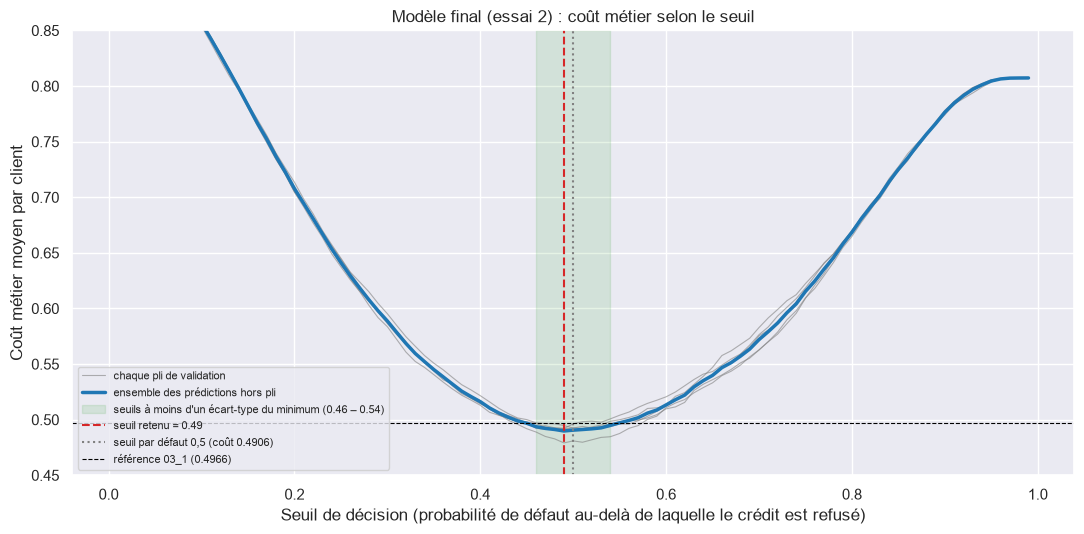

Seuil retenu : 0.49 | coût hors pli : 0.4898 (± 0.0055) | coût au seuil 0,5 : 0.4906


In [13]:
chosen_trial_number = 2  # 2 = parcimonie (retenu) ; 17 = meilleur coût
chosen_trial = study.trials[chosen_trial_number]
final_params = chosen_trial.params

# Les probabilités hors pli ne sont pas stockées dans MLflow : on refait la validation croisée de cet essai
oof_proba, val_indices, fold_scores = cross_validate_oof(build_model(final_params), X, y, cv)
costs = cost_by_threshold(y, oof_proba)
final_threshold, final_oof_cost = find_best_threshold(y, oof_proba)
final_scores = scores_at_threshold(y, oof_proba, val_indices, final_threshold)
cost_std = final_scores["test_business_cost_std"]

# Seuils « équivalents » : coût à moins d'un écart-type entre plis du minimum
plateau = costs[costs <= costs.min() + cost_std].index

fig, ax = plt.subplots(figsize=(11, 5.5))
for k, idx in enumerate(val_indices):
    cost_by_threshold(y.iloc[idx], oof_proba[idx]).plot(ax=ax, color="grey", lw=0.8, alpha=0.6,
                                                        label="chaque pli de validation" if k == 0 else "_nolegend_")
costs.plot(ax=ax, color="tab:blue", lw=2.5, label="ensemble des prédictions hors pli")
ax.axvspan(plateau.min(), plateau.max(), color="tab:green", alpha=0.12,
           label=f"seuils à moins d'un écart-type du minimum ({plateau.min():.2f} – {plateau.max():.2f})")
ax.axvline(final_threshold, color="tab:red", ls="--", label=f"seuil retenu = {final_threshold:.2f}")
ax.axvline(0.5, color="grey", ls=":", label=f"seuil par défaut 0,5 (coût {costs.loc[0.5]:.4f})")
ax.axhline(reference_cost, color="black", ls="--", lw=0.8, label=f"référence 03_1 ({reference_cost:.4f})")
ax.set_ylim(0.45, 0.85)
ax.set_xlabel("Seuil de décision (probabilité de défaut au-delà de laquelle le crédit est refusé)")
ax.set_ylabel("Coût métier moyen par client")
ax.set_title(f"Modèle final (essai {chosen_trial_number}) : coût métier selon le seuil")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "04_1_cout_seuil_modele_final.png", dpi=120)
plt.show()

print(f"Seuil retenu : {final_threshold:.2f} | coût hors pli : {final_scores['average_test_business_cost']:.4f} "
      f"(± {cost_std:.4f}) | coût au seuil 0,5 : {costs.loc[0.5]:.4f}")


Lecture du graphique :

- **Résultat :** le seuil retenu est 0,49, pour un coût hors pli d'environ 0,490, contre 0,4966 pour la référence.

- **Robustesse du seuil :**
    - Les 5 courbes grises (une par pli, difficilement visibles) se superposent presque parfaitement à la bleue, et leur creux tombe au même endroit (entre 0,49 et 0,5), bien que ce soit à cet endroit que leur écart (entre la plus haute et la plus basse) est le plus fort. Le seuil ne dépend pas du hasard du découpage.
    - La zone verte regroupe les seuils statistiquement équivalents. Une petite erreur de réglage du seuil dans cette zone ne coûte presque rien (la courbe bleue y est presque plate). En dehors de cette zone, les erreurs deviennent nettement plus chères : la pente de la courbe s'accentue, et au seuil 0,3 le coût atteint déjà environ 0,58.

- **Un seuil proche de 0,5 :** le seuil optimal (0,49) est presque égal au seuil par défaut de 0,5. Ce n'est pas un hasard : `class_weight="balanced"` donne aux défauts un poids de 11,4, très proche du rapport de coût FN / FP = 10. La pondération et le seuil corrigent le même déséquilibre ; ici, la pondération en a fait presque tout le travail, et la courbe le confirme. Le seuil de 0,5 n'est donc pas une hypothèse par défaut mais un résultat de l'optimisation.

- **Chiffre le plus important :** le coût au seuil 0,5 vaut 0,4906, presque le même qu'au seuil 0,49.

## 8. Robustesse du modèle

La robustesse désigne la stabilité des résultats d'un pli à l'autre, mesurée par le coefficient de variation (écart-type / moyenne) du coût métier. Une valeur autour de 1 % veut dire que le coût varie d'environ 1 % selon les clients tirés : le modèle ne doit pas sa performance à un découpage chanceux.

D'après le tableau ci-dessous, le coût métier vaut 0,4898 ± 0,0061, soit un coefficient de variation de 1,25 % : le modèle est robuste.

Le pli 4 est meilleur que les autres (coût de 0,4791) : c'est un pli « chanceux », que la validation croisée permet de neutraliser. Sur un seul découpage train / test, on aurait pu tomber dessus et surestimer le modèle.

Les métriques :
- **Rappel :** 0,70, très stable (0,74 % de variation) : 7 défauts sur 10 sont détectés.
- **Précision :** 0,185, très stable aussi : moins de 1 refus sur 5 concerne un vrai futur défaut. C'est le prix à payer, et il est assumé puisqu'un FN coûte 10 fois un FP.
- **AUC :** 0,785 en validation contre 0,832 en entraînement, soit un écart de 0,048, identique sur les 5 plis : c'est un surapprentissage léger et régulier.

In [14]:
from src.modeling_functions import classification_metrics

# Métriques de chaque pli de validation, au seuil retenu
per_fold = pd.DataFrame(
    [classification_metrics(y.iloc[idx], (oof_proba[idx] >= final_threshold).astype(int)) for idx in val_indices]
)
per_fold["AUC val"] = fold_scores["test_roc_auc"]
per_fold["AUC train"] = fold_scores["train_roc_auc"]
per_fold.index = [f"pli {k + 1}" for k in range(len(per_fold))]
per_fold = per_fold.rename(columns={"business_cost": "coût métier", "recall": "rappel", "precision": "précision"})

summary = pd.concat([per_fold, per_fold.agg(["mean", "std"]).rename(index={"mean": "moyenne", "std": "écart-type"})])
summary.loc["écart-type / moyenne"] = summary.loc["écart-type"] / summary.loc["moyenne"]

# Run MLflow du modèle final (le modèle lui-même sera ajouté en section 9)
final_metrics = {
    "best_threshold": final_threshold,
    "business_cost_threshold_05": costs.loc[0.5],
    "average_train_roc_auc": np.mean(fold_scores["train_roc_auc"]),
    "average_test_roc_auc": np.mean(fold_scores["test_roc_auc"]),
    "test_roc_auc_std": np.std(fold_scores["test_roc_auc"]),
    **final_scores,
}
final_metrics["overfit_gap_roc_auc"] = final_metrics["average_train_roc_auc"] - final_metrics["average_test_roc_auc"]

with mlflow.start_run(
    run_name="lightgbm_final",
    tags={"etape": "4 - optimisation", "notebook": "04_1_optimisation_seuil", "famille_modele": "boosting",
          "gestion_desequilibre": "class_weight", "type_run": "modele_final", "optuna_trial": chosen_trial_number},
    description=f"Modèle final : LightGBM balanced, hyperparamètres de l'essai Optuna n°{chosen_trial_number}, "
                f"seuil métier {final_threshold:.2f} choisi sur les prédictions hors pli (5 plis).",
) as final_run:
    mlflow.log_input(dataset_abstraction, context="training")
    mlflow.log_params({**FIXED_PARAMS, **final_params, "decision_threshold": final_threshold,
                       "n_splits": n_splits, "cost_fn": COST_FN, "cost_fp": COST_FP})
    mlflow.log_metrics(final_metrics)
    mlflow.log_figure(fig, "cost_vs_threshold.png")  # la figure de la cellule 12
    mlflow.log_table(summary.reset_index(names="pli"), "metriques_par_pli.json")

print(f"Run MLflow du modèle final : {final_run.info.run_id}")
summary.style.format(precision=4).set_properties(subset=pd.IndexSlice[["moyenne", "écart-type"], :], **{"font-weight": "bold"})


Run MLflow du modèle final : 50716a9367c9484ab1b4f0635ad10917


/opt/anaconda3/envs/medef/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


,coût métier,rappel,précision,f1,accuracy,AUC val,AUC train
pli 1,0.4920,0.6969,0.1853,0.2928,0.7282,0.7856,0.8325
pli 2,0.4947,0.7019,0.1824,0.2895,0.7219,0.7826,0.8331
pli 3,0.4911,0.7017,0.1845,0.2922,0.7256,0.7836,0.8320
pli 4,0.4791,0.7112,0.1892,0.2989,0.7307,0.7868,0.8320
pli 5,0.4921,0.7029,0.1836,0.2912,0.7237,0.7848,0.8323
moyenne,0.4898,0.7029,0.1850,0.2929,0.7260,0.7847,0.8324
écart-type,0.0061,0.0052,0.0026,0.0036,0.0035,0.0016,0.0005
écart-type / moyenne,0.0125,0.0074,0.0141,0.0122,0.0048,0.0021,0.0006


## 9. Évaluation unique sur le jeu de test

In [15]:
from mlflow.models import infer_signature
from sklearn.metrics import confusion_matrix, roc_auc_score

# 1. Entraînement du modèle final sur TOUT le train (les 5 plis réunis)
final_model = build_model(final_params).fit(X, y)

# 2. Première et unique lecture du jeu de test
test = pd.read_parquet(TEST_FILE)
X_test = test[features_used].astype("float32")
y_test = test[TARGET]
del test

# 3. Prédictions au seuil métier retenu en section 7 (aucun réglage sur le test)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= final_threshold).astype(int)
test_metrics = {f"holdout_{name}": value for name, value in classification_metrics(y_test, test_pred).items()}
test_metrics["holdout_roc_auc"] = roc_auc_score(y_test, test_proba)

# 4. Comparaison validation croisée / test
comparison_cv_test = pd.DataFrame({
    "validation croisée (train)": [final_scores["average_test_business_cost"], final_metrics["average_test_roc_auc"],
                                   final_scores["average_test_recall"], final_scores["average_test_precision"],
                                   final_scores["average_test_accuracy"]],
    "test (jamais vu)": [test_metrics["holdout_business_cost"], test_metrics["holdout_roc_auc"],
                         test_metrics["holdout_recall"], test_metrics["holdout_precision"],
                         test_metrics["holdout_accuracy"]],
}, index=["coût métier", "AUC", "rappel", "précision", "accuracy"])
comparison_cv_test["écart"] = comparison_cv_test["test (jamais vu)"] - comparison_cv_test["validation croisée (train)"]

# 5. Matrice de confusion ramenée à 10 000 demandes de crédit
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
per_10k = 10_000 / len(y_test)
print(f"Sur 10 000 demandes : {tp * per_10k:.0f} défauts refusés (VP) | {fn * per_10k:.0f} défauts accordés (FN, coût 10) | "
      f"{fp * per_10k:.0f} bons clients refusés (FP, coût 1) | {tn * per_10k:.0f} bons clients accordés (VN)")

# 6. Ajout des résultats ET du modèle au run MLflow du modèle final
with mlflow.start_run(run_id=final_run.info.run_id):
    mlflow.log_metrics(test_metrics)
    mlflow.sklearn.log_model(
        final_model,
        name="model",
        signature=infer_signature(X_test.head(100), final_model.predict_proba(X_test.head(100))[:, 1]),
        input_example=X_test.head(3),
        skops_trusted_types=[  # types de notre propre modèle LightGBM, déclarés sûrs pour le rechargement
            "collections.OrderedDict",
            "lightgbm.basic.Booster",
            "lightgbm.sklearn.LGBMClassifier",
        ],
    )

comparison_cv_test.style.format(precision=4)


Sur 10 000 demandes : 574 défauts refusés (VP) | 234 défauts accordés (FN, coût 10) | 2517 bons clients refusés (FP, coût 1) | 6676 bons clients accordés (VN)


2026/11/02 18:09:14 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/tmphshfdar0/model/model.skops, flavor: sklearn). Fall back to return ['scikit-learn==1.9.1', 'skops==0.16.0']. Set logging level to DEBUG to see the full traceback. 


,validation croisée (train),test (jamais vu),écart
coût métier,0.4898,0.4853,-0.0045
AUC,0.7847,0.7874,0.0027
rappel,0.7029,0.7106,0.0077
précision,0.1850,0.1856,0.0006
accuracy,0.7260,0.7250,-0.0011


## 10. Conclusion